In [1]:
from google.colab import drive
import pandas as pd


In [2]:
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
netflix_dataset= pd.read_csv('/content/drive/MyDrive/Netflix/combined_data_1.txt',header=None,names=['customer_id', 'rating'],usecols=[0,1])

In [13]:

netflix_dataset

,customer_id,rating
0,1:,NaN
1,1488844,3.0
2,822109,5.0
3,885013,4.0
4,30878,4.0
...,...,...
24058258,2591364,2.0
24058259,1791000,2.0
24058260,512536,5.0
24058261,988963,3.0


In [14]:
movie_count=netflix_dataset.isnull().sum()['rating']

In [15]:
movie_count

np.int64(4499)

In [16]:
total_count=netflix_dataset['customer_id'].nunique()

In [17]:
customer_count=total_count-movie_count
customer_count

np.int64(470758)

In [18]:
stars=netflix_dataset.groupby('rating')['rating'].count()

In [19]:
stars

,rating
rating,
1.0,1118186
2.0,2439073
3.0,6904181
4.0,8085741
5.0,5506583


In [20]:
netflix_dataset['rating'].value_counts()

,count
rating,
4.0,8085741
3.0,6904181
5.0,5506583
2.0,2439073
1.0,1118186


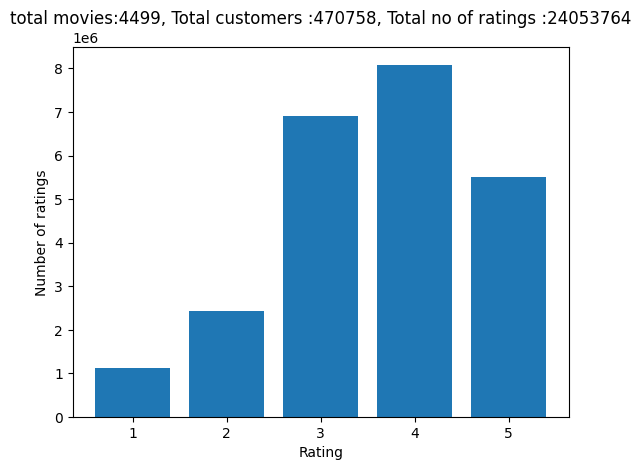

In [ ]:
import matplotlib.pyplot as plt

plt.bar(stars.index, stars.values)
plt.xlabel('Rating')
plt.ylabel('Number of ratings')
plt.title('total movies:' + str(movie_count) + ', Total customers :' + str(customer_count) + ', Total no of ratings :' + str(rating_count))
plt.show()

In [21]:
rating_count=netflix_dataset['customer_id'].count()- movie_count

In [22]:
rating_count

np.int64(24053764)

In [23]:

row= netflix_dataset[netflix_dataset['customer_id']=='2:'].sum()

In [24]:
row

,0
customer_id,2:
rating,0.0


In [25]:
movie_id=None
movie_np=[]
for i in netflix_dataset['customer_id']:
  if ':' in i:
    movie_id=int(i.replace(':',""))
  movie_np.append(movie_id)

In [26]:
netflix_dataset['movie_id']=movie_np

In [27]:
netflix_dataset

,customer_id,rating,movie_id
0,1:,NaN,1
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499


In [28]:
netflix_dataset=netflix_dataset[netflix_dataset['rating'].notna()]

In [29]:


netflix_dataset

,customer_id,rating,movie_id
1,1488844,3.0,1
2,822109,5.0,1
3,885013,4.0,1
4,30878,4.0,1
5,823519,3.0,1
...,...,...,...
24058258,2591364,2.0,4499
24058259,1791000,2.0,4499
24058260,512536,5.0,4499
24058261,988963,3.0,4499


In [30]:
netflix_dataset['customer_id']=netflix_dataset['customer_id'].astype(int)

/tmp/ipykernel_2367/1827080267.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  netflix_dataset['customer_id']=netflix_dataset['customer_id'].astype(int)


In [31]:

netflix_dataset.info()

<class 'pandas.core.frame.DataFrame'>
Index: 24053764 entries, 1 to 24058262
Data columns (total 3 columns):
 #   Column       Dtype  
---  ------       -----  
 0   customer_id  int64  
 1   rating       float64
 2   movie_id     int64  
dtypes: float64(1), int64(2)
memory usage: 734.1 MB


In [32]:

dataset_movie_summary= netflix_dataset.groupby('movie_id')['rating'].agg(['count'])

In [33]:


dataset_movie_summary

,count
movie_id,
1,547
2,145
3,2012
4,142
5,1140
...,...
4495,614
4496,9519
4497,714


In [34]:
movie_benchmark=round(dataset_movie_summary['count'].quantile(0.6),0)

In [35]:
movie_benchmark

np.float64(908.0)

In [36]:
movie_droplist= dataset_movie_summary[dataset_movie_summary['count']<movie_benchmark].index

In [37]:
movie_droplist

Index([   1,    2,    4,    7,    9,   10,   11,   12,   13,   14,
       ...
       4480, 4481, 4486, 4487, 4491, 4494, 4495, 4497, 4498, 4499],
      dtype='int64', name='movie_id', length=2699)

In [38]:
netflix_dataset=netflix_dataset[~netflix_dataset['movie_id'].isin(movie_droplist)]

In [39]:
netflix_dataset

,customer_id,rating,movie_id
695,1025579,4.0,3
696,712664,5.0,3
697,1331154,4.0,3
698,2632461,3.0,3
699,44937,5.0,3
...,...,...,...
24056844,267802,4.0,4496
24056845,1559566,3.0,4496
24056846,293198,3.0,4496
24056847,70814,2.0,4496


In [40]:
df_title=pd.read_csv('/content/drive/MyDrive/Netflix/movies (1) (1).csv',encoding='ISO-8859-1',
    usecols=[0, 1, 2])

In [41]:
df_title

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
27273,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27274,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27275,131258,The Pirates (2014),Adventure
27276,131260,Rentun Ruusu (2001),(no genres listed)


In [7]:
!pip install scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 24.9 MB/s eta 0:00:00


In [8]:
from surprise import Reader,Dataset,SVD
from surprise.model_selection import cross_validate

In [9]:
reader = Reader()

In [42]:
data = Dataset.load_from_df(
    netflix_dataset[['customer_id','movie_id','rating']][:100000], reader
)

In [43]:
model = SVD()

In [44]:
cross_validate(model,data,measures=['RMSE'],cv=3)


{'test_rmse': array([1.04479362, 1.05050122, 1.04266238]),
 'fit_time': (2.8562941551208496, 1.3758831024169922, 1.4684019088745117),
 'test_time': (0.5569038391113281, 0.1698150634765625, 0.1651303768157959)}

In [46]:
user_rating = netflix_dataset[netflix_dataset['customer_id'] == 1331154]


In [47]:
user_rating

,customer_id,rating,movie_id
697,1331154,4.0,3
5178,1331154,4.0,8
31460,1331154,3.0,18
92840,1331154,4.0,30
224761,1331154,3.0,44
...,...,...,...
23439584,1331154,4.0,4389
23546489,1331154,2.0,4402
23649431,1331154,4.0,4432
23844441,1331154,3.0,4472


In [48]:
user_1331154 = df_title.copy()

In [49]:
user_1331154

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
27273,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27274,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27275,131258,The Pirates (2014),Adventure
27276,131260,Rentun Ruusu (2001),(no genres listed)


In [53]:
user_1331154=user_1331154[~user_1331154['movieId'].isin(movie_droplist)]

In [54]:
user_1331154

,movieId,title,genres
2,3,Grumpier Old Men (1995),Comedy|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
7,8,Tom and Huck (1995),Adventure|Children
15,16,Casino (1995),Crime|Drama
...,...,...,...
27273,131254,Kein Bund fÃ¼r's Leben (2007),Comedy
27274,131256,"Feuer, Eis & Dosenbier (2002)",Comedy
27275,131258,The Pirates (2014),Adventure
27276,131260,Rentun Ruusu (2001),(no genres listed)


In [57]:
user_1331154['Estimated_Score'] = user_1331154['movieId'].apply(lambda x : model.predict(1331154,x).est)

/tmp/ipykernel_2367/4168108311.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_1331154['Estimated_Score'] = user_1331154['movieId'].apply(lambda x : model.predict(1331154,x).est)


In [58]:
model.predict(1331154,1)

Prediction(uid=1331154, iid=1, r_ui=None, est=np.float64(3.5862036387139526), details={'was_impossible': False})

In [59]:
user_1331154

,movieId,title,genres,Estimated_Score
2,3,Grumpier Old Men (1995),Comedy|Romance,3.790475
4,5,Father of the Bride Part II (1995),Comedy,3.953406
5,6,Heat (1995),Action|Crime|Thriller,3.495311
7,8,Tom and Huck (1995),Adventure|Children,3.802468
15,16,Casino (1995),Crime|Drama,3.441648
...,...,...,...,...
27273,131254,Kein Bund fÃ¼r's Leben (2007),Comedy,3.586204
27274,131256,"Feuer, Eis & Dosenbier (2002)",Comedy,3.586204
27275,131258,The Pirates (2014),Adventure,3.586204
27276,131260,Rentun Ruusu (2001),(no genres listed),3.586204


In [60]:
user_1331154.sort_values('Estimated_Score',ascending=False,inplace=True)

/tmp/ipykernel_2367/1633114484.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  user_1331154.sort_values('Estimated_Score',ascending=False,inplace=True)


In [61]:
user_1331154

,movieId,title,genres,Estimated_Score
17,18,Four Rooms (1995),Comedy,3.974092
27,28,Persuasion (1995),Drama|Romance,3.972850
24,25,Leaving Las Vegas (1995),Drama|Romance,3.956923
4,5,Father of the Bride Part II (1995),Comedy,3.953406
29,30,Shanghai Triad (Yao a yao yao dao waipo qiao) ...,Crime|Drama,3.875064
...,...,...,...,...
5,6,Heat (1995),Action|Crime|Thriller,3.495311
15,16,Casino (1995),Crime|Drama,3.441648
23,24,Powder (1995),Drama|Sci-Fi,3.237746
25,26,Othello (1995),Drama,2.964758


In [62]:
user_1331154.head(5)

,movieId,title,genres,Estimated_Score
17,18,Four Rooms (1995),Comedy,3.974092
27,28,Persuasion (1995),Drama|Romance,3.972850
24,25,Leaving Las Vegas (1995),Drama|Romance,3.956923
4,5,Father of the Bride Part II (1995),Comedy,3.953406
29,30,Shanghai Triad (Yao a yao yao dao waipo qiao) ...,Crime|Drama,3.875064
